<img src='../OUTILS/bandeau_MF.png' align='right' width='100%'/>

# <div style='background-color: #1e3c72; color: white; padding: 20px; border-radius: 10px; text-align: center;'>🌍🛰️ Fusion & Sandwich – Données satellitaires</div>

---

## 🎯 **Objectifs du TP**

- 🧩 Faire une **fusion** d'images.
- 🥪 Réaliser une image **sandwich** (VIS + IR colorisée)
- 🎨 Ajouter de la transparence et des masques

---

## 🧰 **Outils utilisés**

| Outil | Rôle |
|-------|------|
| **GDAL** | Manipulation géospatiale (warp, info, rasterize) |
| **ImageMagick** | Conversion, redimensionnement, annotations |
| **Python (numpy)** | Calculs de fusion personnalisés |

---

## 📂 **Fichiers utilisés**

- **VIS006** : canal visible (haute résolution, gris)
- **IR105** : canal infrarouge thermique (résolution plus faible)
- **ConvStorm** : produit RGB convection

> 💡 *Données opérationnelles du CMS Météo-France, satellite Meteosat-12*

<div class="alert alert-info" role="alert">
<h3> ⚙️ Initialisation de l'environnement</h3>
Importation des librairies et configuration des chemins.
</div>

In [1]:
from datetime import datetime
import os
import numpy as np
from osgeo import gdal
from PIL import Image
from IPython.display import display

# Environnement GDAL/PROJ
os.environ['PATH'] = f"/opt/conda/env_MF_teledetection/bin:{os.environ['PATH']}" 
os.environ['PATH'] = f"~/.conda/envs/env_MF_teledetection/bin:{os.environ['PATH']}"
os.environ['GDAL_DATA'] = '/opt/conda/env_MF_teledetection/share/gdal'
os.environ['PROJ_LIB'] = '/opt/conda/env_MF_teledetection/share/proj'


In [2]:
cd ~/MF_DATA_MANIPULATION

/home/coster/MF_DATA_MANIPULATION


In [3]:
# Dossier de travail
!mkdir -p RESULTS
output = 'RESULTS'

#❗ Attention : ce chemin doit-être modifié pour toute arborescence différente
data_dir = "/stockage/DATA/20260509"
#data_dir = "/stockage/DATA/20260509"

VIS006 = "20260509_1500_meteosat12_europe_vis006"
IR105 = "20260509_1500_meteosat12_europe_ir105"
Convection = "20260509_1500_meteosat12_europe_ConvStorm"
Airmass = "20260509_1500_meteosat12_europe_airmass"

print(f"📁 Dossier source : {data_dir}")
print(f"📸 VIS006 : {VIS006}.tif")
print(f"🌡️ IR105  : {IR105}.tif")
print(f"⛈️ Convection : {Convection}.tif")

📁 Dossier source : /stockage/DATA/20260509
📸 VIS006 : 20260509_1500_meteosat12_europe_vis006.tif
🌡️ IR105  : 20260509_1500_meteosat12_europe_ir105.tif
⛈️ Convection : 20260509_1500_meteosat12_europe_ConvStorm.tif


## 📖 **Définitions : Fusion, Sandwich**

<div class="alert alert-success" style="background-color: #d4edda; padding: 15px; border-radius: 10px;">

### 🧩 **Fusion d’images**
Combinaison de plusieurs images (souvent de sources différentes) pour obtenir une image unique.

*Exemple simple* : remplacer une zone d’une image par une autre (masque binaire).

### 🥪 **Sandwich**
Technique de fusion où l’on superpose une image **colorisée** (ex : IR thermique) sur une image **à haute résolution** (ex : visible) en utilisant un **canal alpha** (transparence).
On obtient un rendu où les structures fines (nuages, côtes) sont conservées tout en ajoutant l’information colorée.

</div>

---

## 📊 **Tableau comparatif**

| Méthode | Principe | Avantages | Inconvénients | Exemple d'usage |
|---------|----------|-----------|---------------|-----------------|
| **Fusion simple** | Remplacement par masque binaire | Simple, rapide | Coupure franche (artefacts de bord) | Mosaïque, masquage de zones |
| **Sandwich** | Superposition avec transparence (alpha) | Conservation des textures fines, transition douce | Nécessite une image avec canal alpha | Météo : nuages colorés sur fond visible |

---

<div class="alert alert-info alert-success">
<h3> 1 - 🖼️ Préparation des données</h3>
</div>

Nous allons :
- Convertir le VIS006 (monocanal) en **fausse image RGB** (3 canaux identiques)
- Coloriser l’IR105 avec une palette (transparence `-alpha`)
- Redimensionner et convertir en JPG pour visualisation

In [ ]:
pwd

In [4]:
# Conversion VIS -> RGB (3 bandes identiques)
!gdal_calc.py -A {data_dir}/{VIS006}.tif --outfile={output}/red.tif --calc="A" --quiet  # extrait bande rouge
!gdal_calc.py -A {data_dir}/{VIS006}.tif --outfile={output}/green.tif --calc="A" --quiet  # extrait bande verte
!gdal_calc.py -A {data_dir}/{VIS006}.tif --outfile={output}/blue.tif --calc="A" --quiet  # extrait bande bleue
!gdal_merge.py -separate -o {output}/{VIS006}_rgb.tif {output}/red.tif {output}/green.tif {output}/blue.tif > /dev/null 2>&1  # fusionne les 3 bandes
print("✅ VIS006 converti en RGB")

✅ VIS006 converti en RGB


In [5]:
cat OUTILS/palette_sandwich_dn_transp.txt

322: 170 140 255 255
310: 218 126 254 255
300: 242 184 234 255
290: 168 134 138 255
280: 80 30 10 255
270: 165 17 69 255
260: 190 77 79 255
250: 215 62 64 255
240: 245 158 93 255
230: 250 204 119 255
220: 250 254 154 255
210: 235 244 189 255
200: 196 226 204 255
190: 155 204 212 255
180: 130 174 212 255
170: 105 144 212 255
169: 0 0 0 0 


In [6]:
# Colorisation de l'IR105 avec palette + alpha
!gdaldem color-relief {data_dir}/{IR105}.tif OUTILS/palette_sandwich_dn_transp.txt {output}/{IR105}_colorisee.tif -alpha  # applique palette et ajoute transparence
print("✅ IR105 colorisé avec transparence")

0...10...20...30...40...50...60...70...80...90...100 - done.
✅ IR105 colorisé avec transparence




🔍 Image VIS006 RGB (rééchantillonnée) :


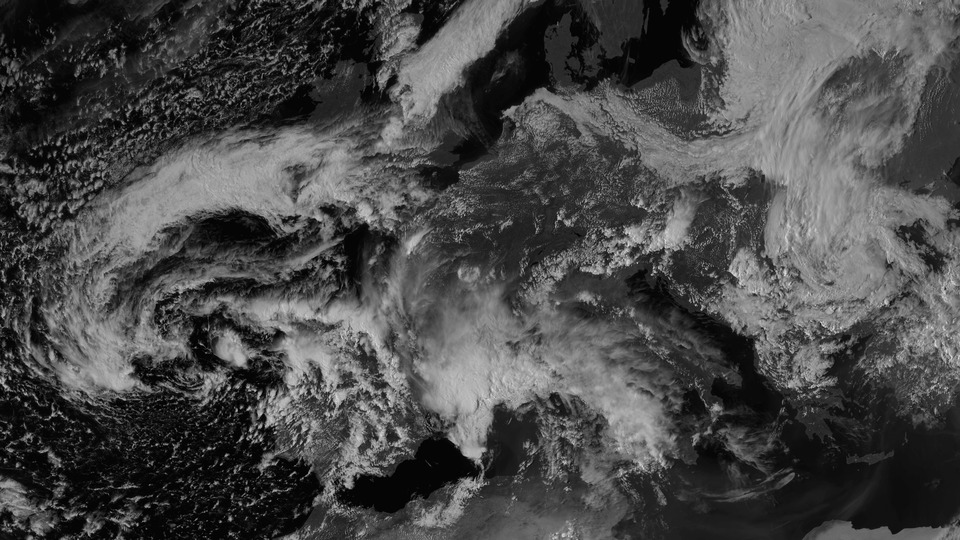

🎨 Image IR105 colorisée (avec transparence) :


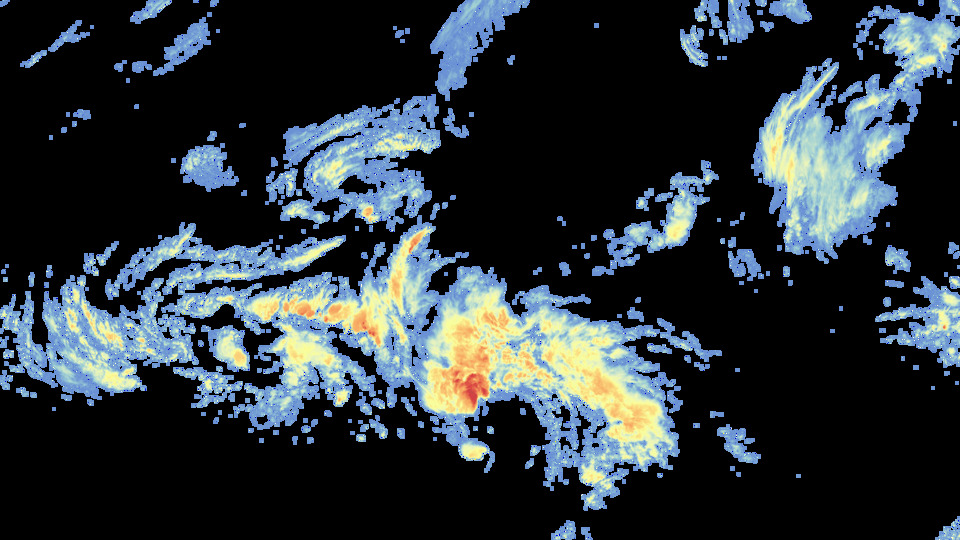

In [7]:
# Miniatures pour visualisation
!convert -resize 960x540 {output}/{VIS006}_rgb.tif {output}/{VIS006}_rgb_min.jpg  # réduit taille pour affichage
!convert -resize 960x540 {output}/{IR105}_colorisee.tif {output}/{IR105}_colorisee_min.jpg

print("🔍 Image VIS006 RGB (rééchantillonnée) :")
display(Image.open(f"{output}/{VIS006}_rgb_min.jpg"))
print("🎨 Image IR105 colorisée (avec transparence) :")
display(Image.open(f"{output}/{IR105}_colorisee_min.jpg"))

### Zoom sur la zone ouest méditerranéenne : découpe en projection "ortho" 



🔍 Image VIS006 RGB - découpe (rééchantillonnée) :


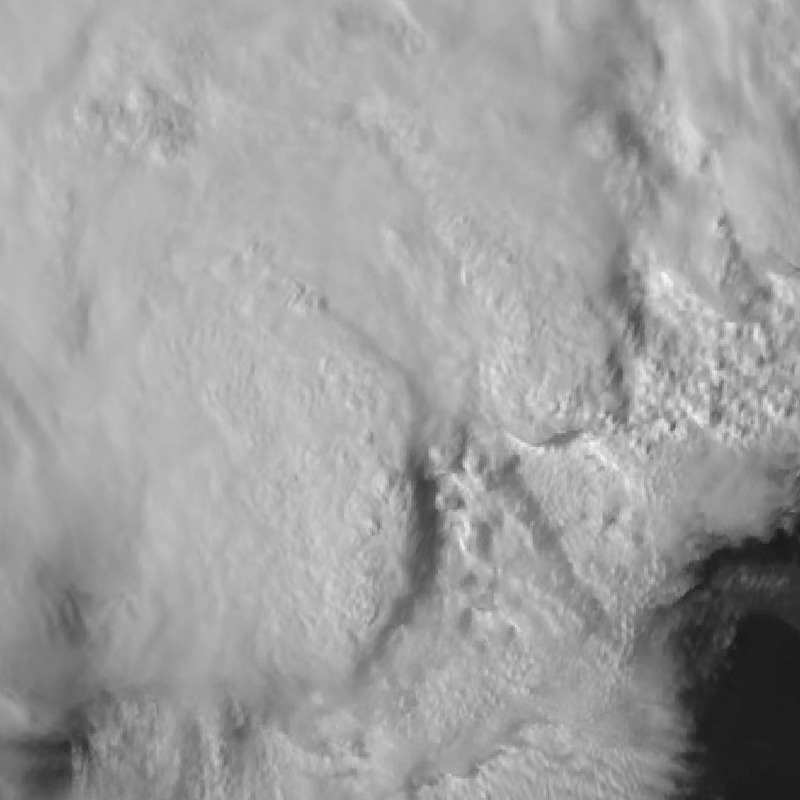

🎨 Image IR105 colorisée - découpe (avec transparence) :


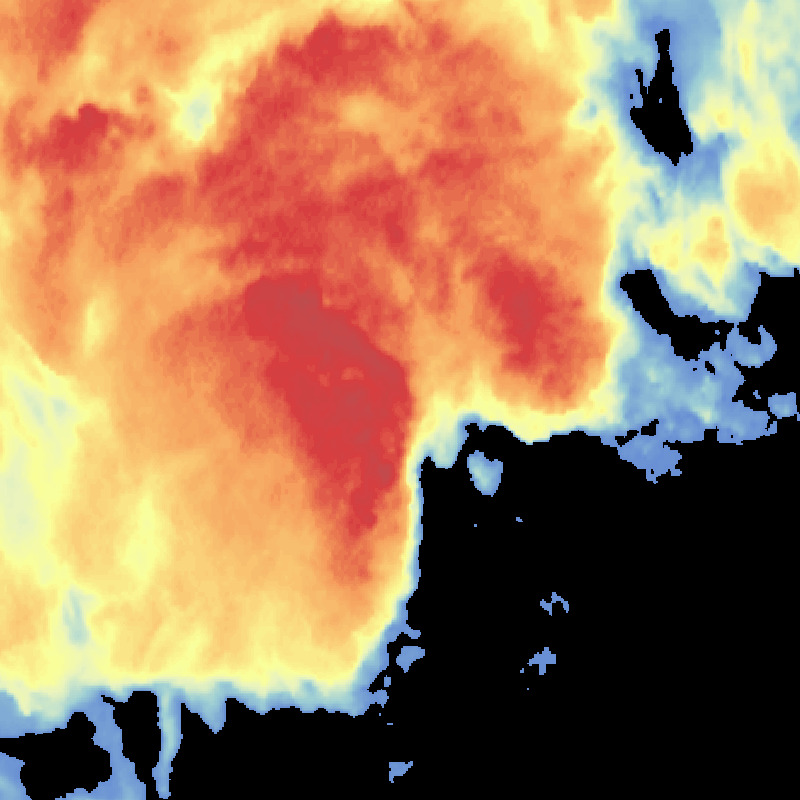

In [8]:
latitude=40.5
longitude=2.7
domaine="-120000 -120000 120000 120000"
taille_sortie="800 800"
!gdalwarp -q -overwrite -t_srs "+proj=ortho lat_0={latitude} lon_0={longitude}" -te {domaine} -ts {taille_sortie} {output}/{VIS006}_rgb.tif {output}/{VIS006}_rgb_decoupe.tif  # reprojette en ortho
!gdalwarp -q -overwrite -t_srs "+proj=ortho lat_0={latitude} lon_0={longitude}" -te {domaine} -ts {taille_sortie}  {output}/{IR105}_colorisee.tif {output}/{IR105}_colorisee_decoupe.tif
!convert {output}/{VIS006}_rgb_decoupe.tif {output}/{VIS006}_rgb_decoupe.jpg
!convert {output}/{IR105}_colorisee_decoupe.tif {output}/{IR105}_colorisee_decoupe.jpg
print("🔍 Image VIS006 RGB - découpe (rééchantillonnée) :")
display(Image.open(f"{output}/{VIS006}_rgb_decoupe.jpg"))
print("🎨 Image IR105 colorisée - découpe (avec transparence) :")
display(Image.open(f"{output}/{IR105}_colorisee_decoupe.jpg"))

<div class="alert alert-info alert-success">
<h3> 2 - 🧩 Fusion simple (remplacement par masque binaire)</h3>
</div>

Ici, on remplace les pixels de la VIS par ceux de l'IR **uniquement là où l'IR n'est pas transparent** (alpha > 0).
C’est une **fusion dure** (coupure nette).

/home/coster/.conda/envs/env_MF_teledetection/lib/python3.10/site-packages/osgeo/gdal.py:311: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(



🥪 Fusion simple (masque binaire) :


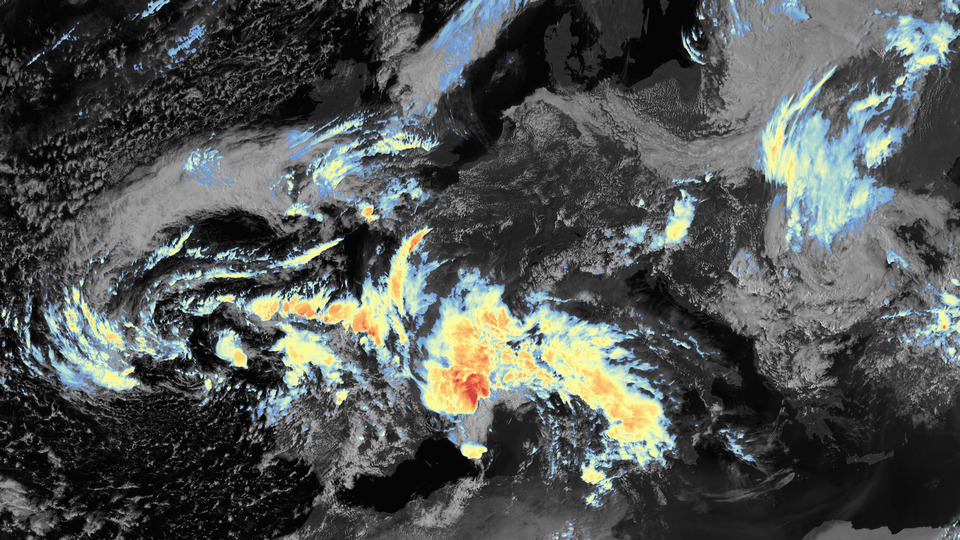

In [9]:
from osgeo import gdal
import numpy as np

vis_ds = gdal.Open(f'{output}/{VIS006}_rgb.tif')
ir_ds = gdal.Open(f'{output}/{IR105}_colorisee.tif')

# Lecture des bandes VIS RGB
vis_r = vis_ds.GetRasterBand(1).ReadAsArray().astype(np.float32)  # canal rouge VIS
vis_g = vis_ds.GetRasterBand(2).ReadAsArray().astype(np.float32)  # canal vert VIS
vis_b = vis_ds.GetRasterBand(3).ReadAsArray().astype(np.float32)  # canal bleu VIS

# Lecture des bandes IR colorisée
ir_r = ir_ds.GetRasterBand(1).ReadAsArray().astype(np.float32)  # canal rouge IR colorisée
ir_g = ir_ds.GetRasterBand(2).ReadAsArray().astype(np.float32)  # canal vert IR
ir_b = ir_ds.GetRasterBand(3).ReadAsArray().astype(np.float32)  # canal bleu IR
ir_a = ir_ds.GetRasterBand(4).ReadAsArray().astype(np.float32)  # canal alpha (transparence)

# Masque binaire (1 si opaque)
mask = (ir_a > 0).astype(np.uint8)

# Fusion : IR si mask=1, sinon VIS
fusion_r = np.where(mask, ir_r, vis_r).astype(np.uint8)  # remplacement par condition
fusion_g = np.where(mask, ir_g, vis_g).astype(np.uint8)
fusion_b = np.where(mask, ir_b, vis_b).astype(np.uint8)

# Sauvegarde
driver = gdal.GetDriverByName('GTiff')
out = driver.Create(f'{output}/fusion_masque_binaire.tif', vis_ds.RasterXSize, vis_ds.RasterYSize, 3, gdal.GDT_Byte)
out.SetProjection(vis_ds.GetProjection())
out.SetGeoTransform(vis_ds.GetGeoTransform())
out.GetRasterBand(1).WriteArray(fusion_r)
out.GetRasterBand(2).WriteArray(fusion_g)
out.GetRasterBand(3).WriteArray(fusion_b)
out = None

!convert -resize 960x540 {output}/fusion_masque_binaire.tif {output}/fusion_masque_binaire_min.jpg
print("🥪 Fusion simple (masque binaire) :")
display(Image.open(f"{output}/fusion_masque_binaire_min.jpg"))

### Zoom sur la zone ouest méditerranéenne


🎨 Image fusion simple - découpe (avec transparence) :


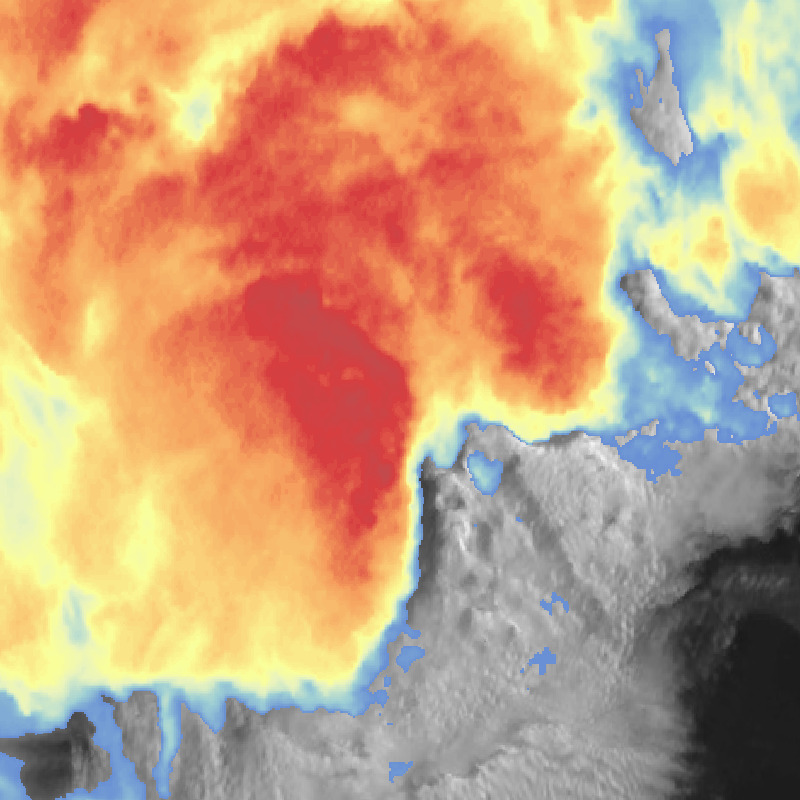

In [10]:
!gdalwarp -q -overwrite -t_srs "+proj=ortho lat_0={latitude} lon_0={longitude}" -te {domaine} -ts {taille_sortie} {output}/fusion_masque_binaire.tif {output}/fusion_vis006_ir105_masque_binaire_decoupe.tif
!convert {output}/fusion_vis006_ir105_masque_binaire_decoupe.tif {output}/fusion_vis006_ir105_masque_binaire_decoupe.jpg
print("🎨 Image fusion simple - découpe (avec transparence) :")
display(Image.open(f"{output}/fusion_vis006_ir105_masque_binaire_decoupe.jpg"))

<div class="alert alert-info alert-success">
<h3> 3 - 🥪 Sandwich</h3>
</div>

Version **multiplicative** : l’IR est multipliée par la VIS, ce qui assombrit les zones colorées tout en conservant les détails fins.
On applique l’effet uniquement là où l’IR est opaque.

On utilise directement le canal alpha de l’IR (gradient de transparence) pour pondérer la fusion.
Le résultat est plus naturel, sans coupure franche.

Paramètre `opacity` : force du sandwich (0 = seule la VIS, 100 = multiplication maximale).


🥪 Sandwich progressif (opacité 85%) :


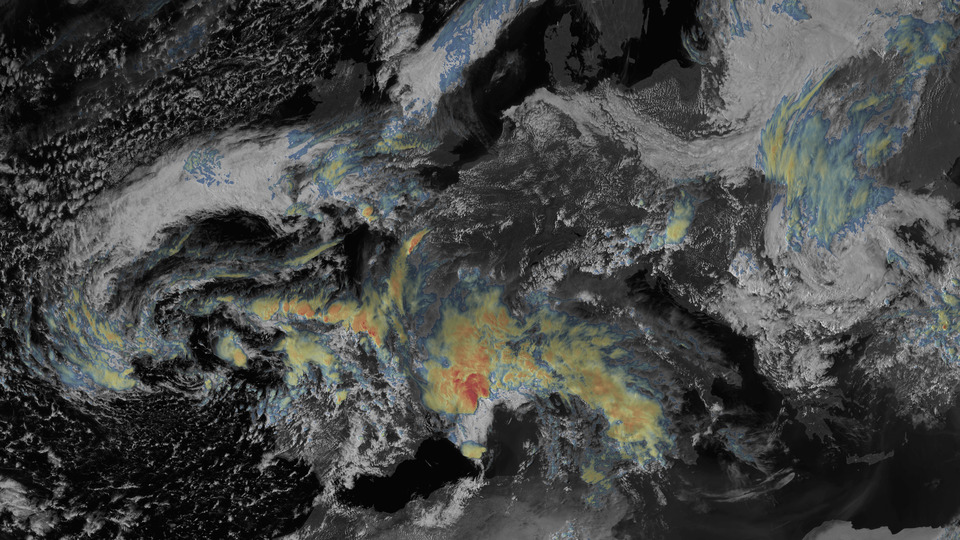

In [11]:
opacity = 85  # à modifier (0-100)

# Normalisation 0-255 → 0-1
vis_norm = (vis_r / 255.0, vis_g / 255.0, vis_b / 255.0)  # images normalisées
ir_norm = (ir_r / 255.0, ir_g / 255.0, ir_b / 255.0)

alpha = ir_a / 255.0  # 0 → transparent, 1 → opaque
facteur = alpha * (opacity / 100.0)  # pondération par opacité choisie

result_r = (ir_norm[0] * vis_norm[0] * facteur + vis_norm[0] * (1 - facteur)) * 255  # fusion multiplicative progressive
result_g = (ir_norm[1] * vis_norm[1] * facteur + vis_norm[1] * (1 - facteur)) * 255
result_b = (ir_norm[2] * vis_norm[2] * facteur + vis_norm[2] * (1 - facteur)) * 255

result_r = np.clip(result_r, 0, 255).astype(np.uint8)  # saturation des valeurs
result_g = np.clip(result_g, 0, 255).astype(np.uint8)
result_b = np.clip(result_b, 0, 255).astype(np.uint8)

out = driver.Create(f'{output}/sandwich_progressif_{opacity}.tif', vis_ds.RasterXSize, vis_ds.RasterYSize, 3, gdal.GDT_Byte)
out.SetProjection(vis_ds.GetProjection())
out.SetGeoTransform(vis_ds.GetGeoTransform())
out.GetRasterBand(1).WriteArray(result_r)
out.GetRasterBand(2).WriteArray(result_g)
out.GetRasterBand(3).WriteArray(result_b)
out = None

!convert -resize 960x540 {output}/sandwich_progressif_{opacity}.tif {output}/sandwich_progressif_{opacity}_min.jpg
print(f"🥪 Sandwich progressif (opacité {opacity}%) :")
display(Image.open(f"{output}/sandwich_progressif_{opacity}_min.jpg"))

### Zoom sur la zone ouest méditerranéenne


🎨 Image Sandwich opacité  - découpe (avec transparence) :


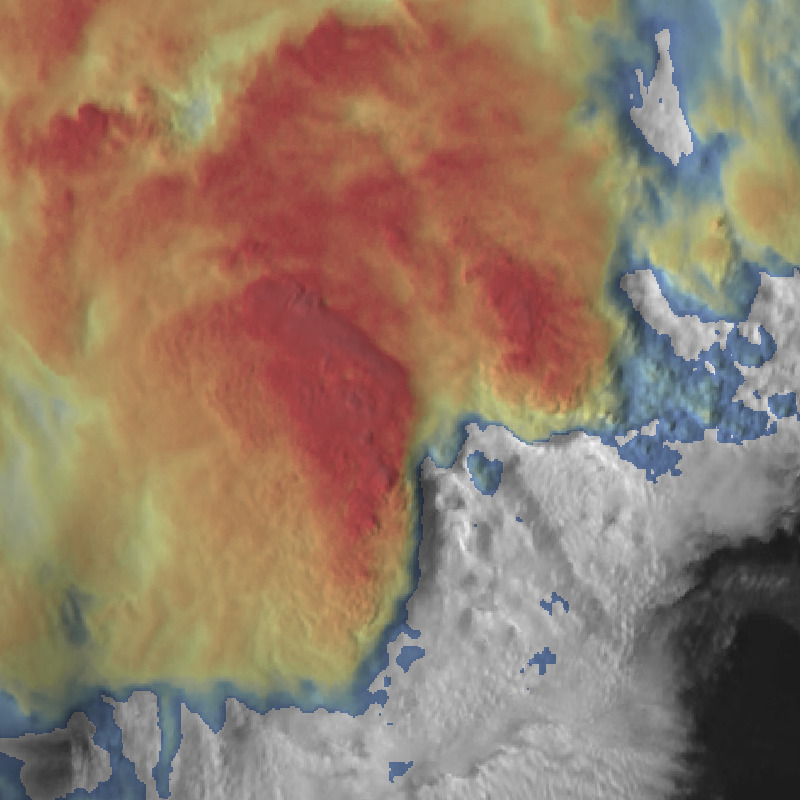

In [12]:
!gdalwarp -q -overwrite -t_srs "+proj=ortho lat_0={latitude} lon_0={longitude}" -te {domaine} -ts {taille_sortie} {output}/sandwich_progressif_{opacity}.tif {output}/sandwich_progressif_{opacity}_decoupe.tif
!convert {output}/sandwich_progressif_{opacity}_decoupe.tif {output}/sandwich_progressif_{opacity}_decoupe.jpg
print("🎨 Image Sandwich opacité  - découpe (avec transparence) :")
display(Image.open(f"{output}/sandwich_progressif_{opacity}_decoupe.jpg"))

### Comparaison des résultats

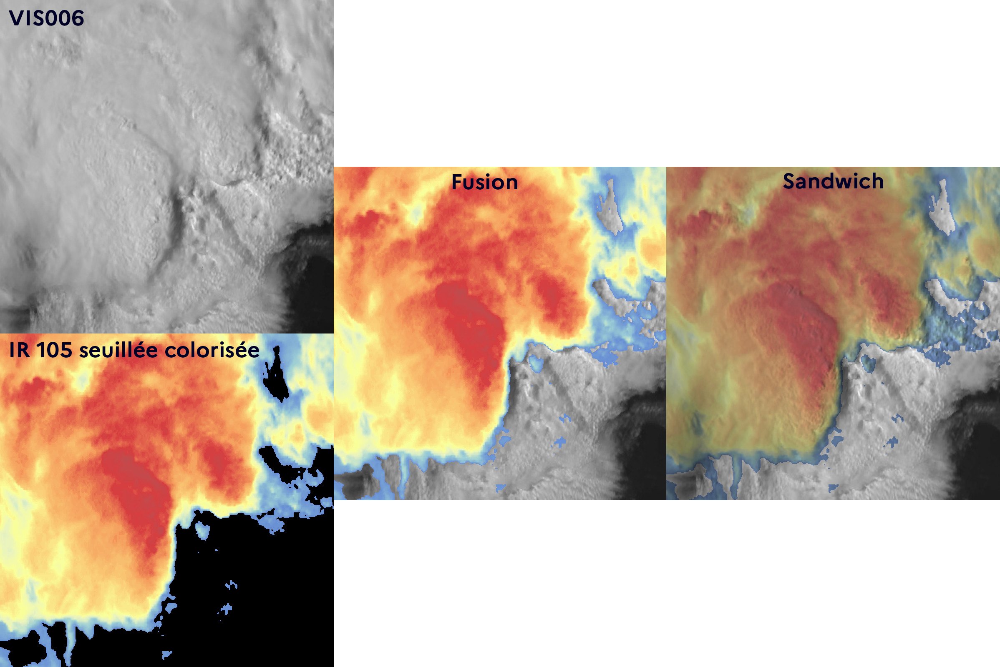

In [13]:
display(Image.open(f"DOCS/20260509_1500_meteosat-12_fusion_et_sandwich.jpg"))


<div class="alert alert-info alert-success">
<h3> 4 - ⛈️ Application au produit Convection RGB</h3>
</div>

On peut utiliser n’importe quelle image RGB avec transparence pour faire un sandwich.
Ici, on va d’abord **masquer** l’image Convection par l’alpha de l’IR, puis la fusionner avec la VIS.

In [14]:
# Application du masque alpha de l'IR à l'image Convection
conv_ds = gdal.Open(f'{data_dir}/{Convection}.tif')
conv_r = conv_ds.GetRasterBand(1).ReadAsArray()
conv_g = conv_ds.GetRasterBand(2).ReadAsArray()
conv_b = conv_ds.GetRasterBand(3).ReadAsArray()

alpha_ir = ir_a  # déjà lu
r_masked = np.where(alpha_ir > 0, conv_r, 0).astype(np.uint8)  # masquage par seuil alpha
g_masked = np.where(alpha_ir > 0, conv_g, 0).astype(np.uint8)
b_masked = np.where(alpha_ir > 0, conv_b, 0).astype(np.uint8)

out_masked = driver.Create(f'{output}/convection_masquee.tif', conv_ds.RasterXSize, conv_ds.RasterYSize, 4, gdal.GDT_Byte)
out_masked.SetProjection(conv_ds.GetProjection())
out_masked.SetGeoTransform(conv_ds.GetGeoTransform())
out_masked.GetRasterBand(1).WriteArray(r_masked)
out_masked.GetRasterBand(2).WriteArray(g_masked)
out_masked.GetRasterBand(3).WriteArray(b_masked)
out_masked.GetRasterBand(4).WriteArray(alpha_ir)  # conserve transparence
out_masked = None

print("✅ Convection masquée par l'alpha de l'IR")

✅ Convection masquée par l'alpha de l'IR



🥪 Sandwich avec Convection RGB (opacité 75%) :


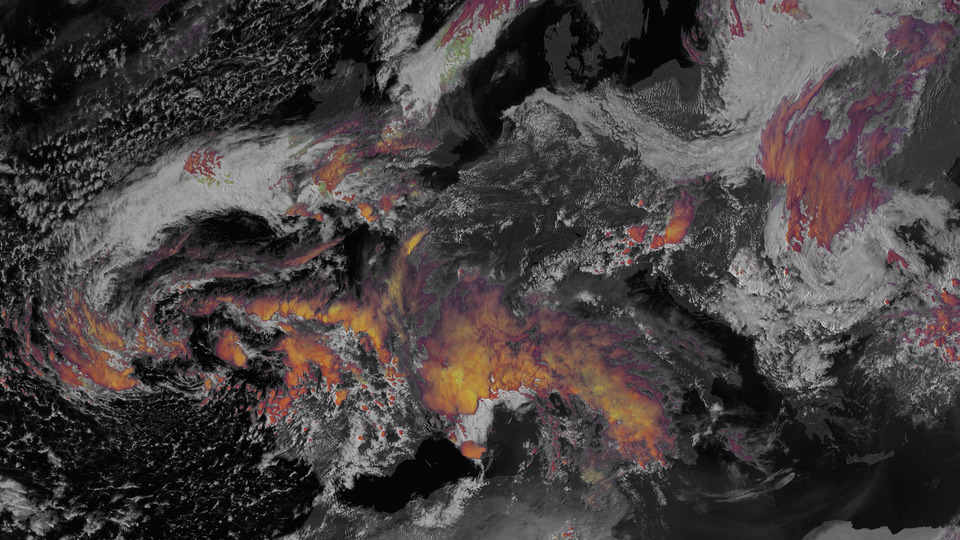

In [15]:
# Sandwich progressif avec Convection masquée

opacity = 75  # à modifier (0-100)

conv_masquee = gdal.Open(f'{output}/convection_masquee.tif')
conv_r_m = conv_masquee.GetRasterBand(1).ReadAsArray().astype(np.float32)
conv_g_m = conv_masquee.GetRasterBand(2).ReadAsArray().astype(np.float32)
conv_b_m = conv_masquee.GetRasterBand(3).ReadAsArray().astype(np.float32)
alpha_conv = conv_masquee.GetRasterBand(4).ReadAsArray().astype(np.float32) / 255.0

conv_norm = (conv_r_m/255, conv_g_m/255, conv_b_m/255)
facteur_conv = alpha_conv * (opacity/100.0)

res_r = (conv_norm[0] * vis_norm[0] * facteur_conv + vis_norm[0] * (1 - facteur_conv)) * 255  # fusion sandwich
res_g = (conv_norm[1] * vis_norm[1] * facteur_conv + vis_norm[1] * (1 - facteur_conv)) * 255
res_b = (conv_norm[2] * vis_norm[2] * facteur_conv + vis_norm[2] * (1 - facteur_conv)) * 255

res_r = np.clip(res_r, 0, 255).astype(np.uint8)
res_g = np.clip(res_g, 0, 255).astype(np.uint8)
res_b = np.clip(res_b, 0, 255).astype(np.uint8)

out_conv = driver.Create(f'{output}/sandwich_convection_{opacity}.tif', vis_ds.RasterXSize, vis_ds.RasterYSize, 3, gdal.GDT_Byte)
out_conv.SetProjection(vis_ds.GetProjection())
out_conv.SetGeoTransform(vis_ds.GetGeoTransform())
out_conv.GetRasterBand(1).WriteArray(res_r)
out_conv.GetRasterBand(2).WriteArray(res_g)
out_conv.GetRasterBand(3).WriteArray(res_b)
out_conv = None

!convert -resize 960x540 {output}/sandwich_convection_{opacity}.tif {output}/sandwich_convection_{opacity}_min.jpg
print(f"🥪 Sandwich avec Convection RGB (opacité {opacity}%) :")
display(Image.open(f"{output}/sandwich_convection_{opacity}_min.jpg"))

### Zoom sur la zone ouest méditerranéenne


🎨 Image Sandwich Convection-Vis  opacité 65  - découpe (avec transparence) :


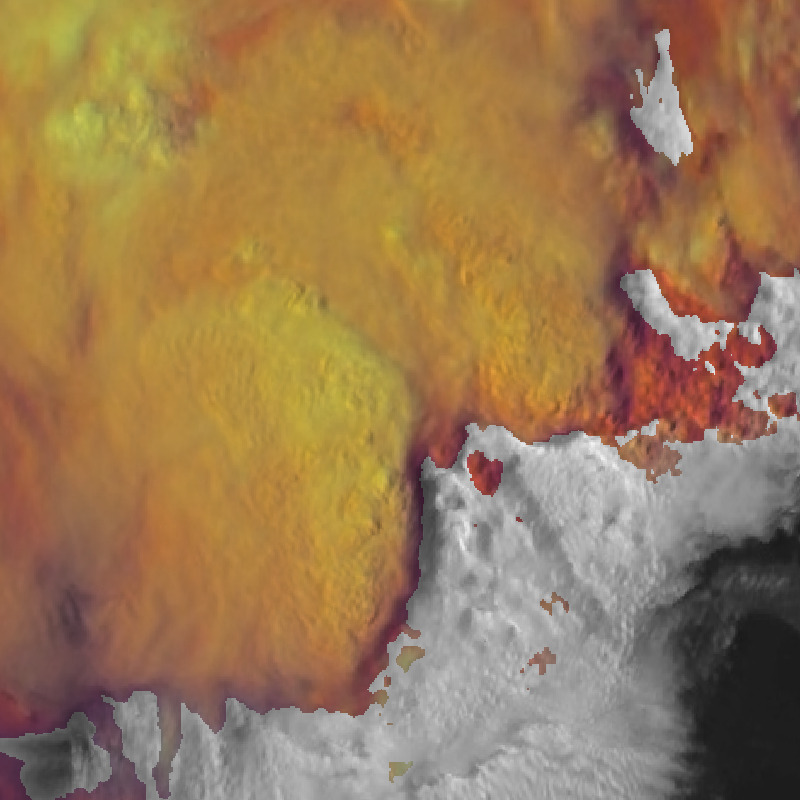

In [16]:
!gdalwarp -q -overwrite -t_srs "+proj=ortho lat_0={latitude} lon_0={longitude}" -te {domaine} -ts {taille_sortie} {output}/sandwich_convection_{opacity}.tif {output}/sandwich_convection_{opacity}_decoupe.tif
!convert {output}/sandwich_convection_{opacity}_decoupe.tif {output}/sandwich_convection_{opacity}_decoupe.jpg
print("🎨 Image Sandwich Convection-Vis  opacité 65  - découpe (avec transparence) :")
display(Image.open(f"{output}/sandwich_convection_{opacity}_decoupe.jpg"))

### Comparaison avec le produit Convection RGB


🎨 Image Convection RGB - découpe :


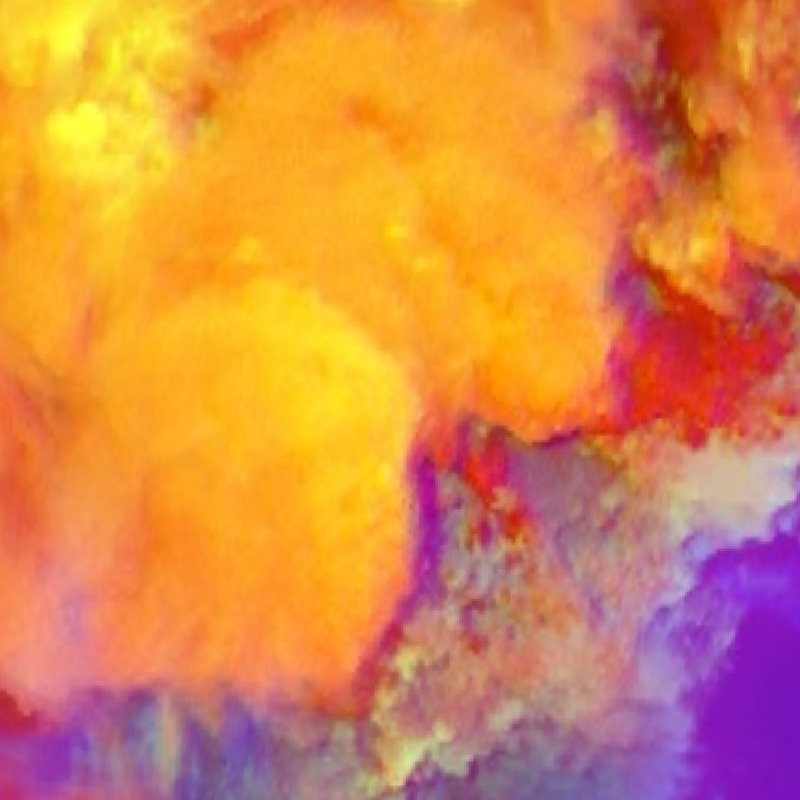

In [17]:
!gdalwarp -q -overwrite -t_srs "+proj=ortho lat_0={latitude} lon_0={longitude}" -te {domaine} -ts {taille_sortie} {data_dir}/20260509_1500_meteosat12_europe_ConvStorm.tif {output}/20260509_1500_meteosat12_europe_ConvStorm_decoupe.tif
!convert {output}/20260509_1500_meteosat12_europe_ConvStorm_decoupe.tif {output}/20260509_1500_meteosat12_europe_ConvStorm_decoupe.jpg
print("🎨 Image Convection RGB - découpe :")
display(Image.open(f"{output}/20260509_1500_meteosat12_europe_ConvStorm_decoupe.jpg"))

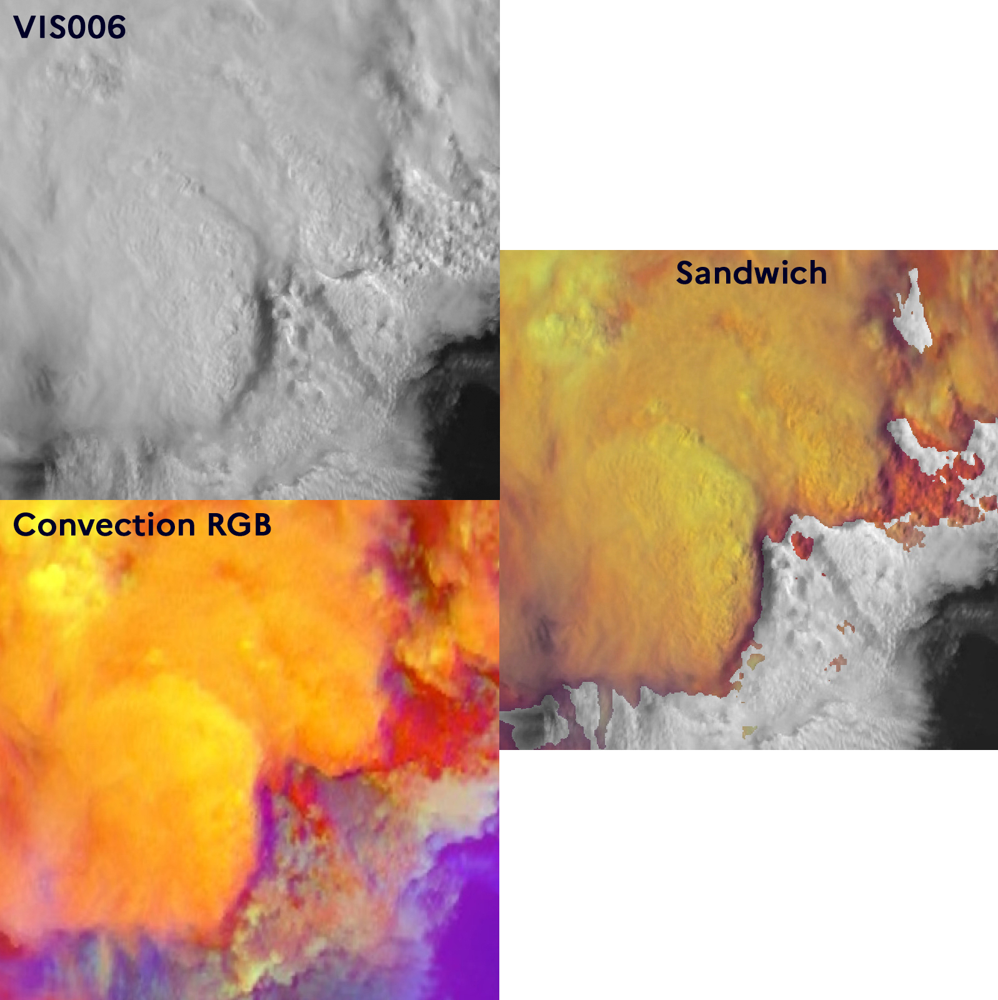

In [18]:
display(Image.open(f"DOCS/20260509_1500_meteosat-12_sandwich_convection.jpg"))


---

✅ **Fin du Notebook**